# TNM112 -- Lab 1
Instructions about the different tasks are specified in this notebook. However, for more details, please see the PDF with lab instructions. Also see the lab report template for information on how to report your results.

### Data generation
Look through the "data_generator.py" code to understand how the dataset is generated and plotted.

The "importlib" library is used to enable reloading of a library each time the cell is executed (so that changes to the imported script will be visible without restarting the notebook).

Data specification:
	Dataset type:           linear
	Number of classes:      4
	Std of classes:         0.4
	Training data shape:    (128, 2)
	Validation data shape:  (2048, 2)
	Test data shape:        (2048, 2)


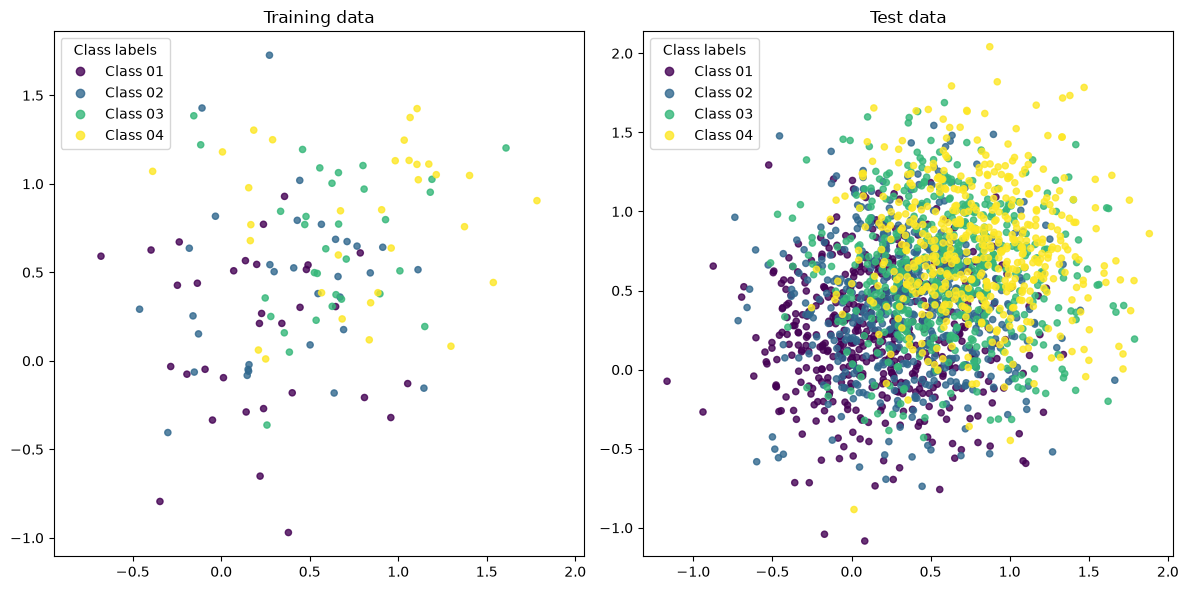

In [13]:
import importlib
import data_generator
importlib.reload(data_generator)

data = data_generator.DataGenerator()
data.generate(dataset='linear', N_train=32, N_test=512, K=4, sigma=0.4)
data.plot()

### PyTorch MLP
Look through the "torch_mlp.py" code to understand how the model is set up, and the "fit" function below to see how it is trained.

#### Task 1.1
Use a linear dataset with N_train = 512 and K = 2. Specify a network without hidden layers. Compare:
* Training for 4 epochs with learning rate 1.0 and batch size 512
* Training for 4 epochs with learning rate 1.0 and batch size 16

Answer the following questions:
* Which model is best at separating the two classes (provide the accuracy on the test set)? Why is this the case? (Hint: how many iterations of SGD are performed in the two cases?)
* Why is it possible to do the classification without non-linear activation function (there's only a softmax activation)?



#### Task 1.2
Use a polar dataset with N_train = 512 and K = 2. Specify a network with one hidden layer with 5 neurons. Train for 20 epochs with learning rate 1.0 and batch size 16. Compare:
* Using linear activation function
* Using sigmoid activation function
* Using relu activation function

Answer the following questions:
* Why does linear activation not work?
* On average, what is the best classification accuracy that can be achieved with a linear activation function?
* Can you find an explanation for the difference comparing sigmoid and relu activation?

#### Task 1.3
Use a polar dataset with N_train = 512, K = 5, and sigma=0.05. Specify a network with 10 hidden layers with 50 neurons each and relu activation. Try different combinations of hyper parameters to get the best classification accuracy. Examples could be:
* Change mean and stddev of normal initialization.
* Change learning rate and add some momentum in SGD.
* Check the PyTorch documentation for 'ExponentialLR', which can be used to specify decaying learning rate for SGD (create it after the optimizer; it is stepped once per epoch, i.e. the learning rate decays by a factor 'gamma' every epoch).
* You can also tweak batch size and number of epochs.

What combination worked best, and what was your best classification accuracy (on the test set)? Can you find any patterns in what combinations of hyper parameters work and doesn't work?

#### Task 1.4
Continue from previous task, but change initialization to 'nn.init.xavier_normal_' and optimizer to 'torch.optim.Adam'. Does this perform better compared to your results in Task 1.3?

Note that the model outputs probabilities (it ends with a softmax), so do not use 'nn.CrossEntropyLoss', which expects raw scores.

In [14]:
import torch_mlp

# Train a model for a number of epochs. Returns a log of the loss and accuracy per epoch.
# Understand what the different parameters mean and how they affect training.
def fit(model, train_loader, val_loader, loss_fn, optimizer, scheduler=None, epochs=100):
    log = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}

    for epoch in range(epochs):
        # One pass over the training data, updating the weights
        loss, acc = torch_mlp.train(train_loader, model, loss_fn, optimizer)
        # Measure performance on the validation data
        val_loss, val_acc = torch_mlp.test(val_loader, model, loss_fn)

        # Learning rate decay (if a scheduler is used), once per epoch.
        # See the PyTorch scheduler docs: https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
        if scheduler is not None:
            scheduler.step()

        log['loss'].append(loss)
        log['accuracy'].append(acc)
        log['val_loss'].append(val_loss)
        log['val_accuracy'].append(val_acc)
        print(f'Epoch {epoch+1}/{epochs} - loss: {loss:.4f} - acc: {acc:.4f} - val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f}')

    return log


Data specification:
	Dataset type:           polar
	Number of classes:      5
	Std of classes:         0.05
	Training data shape:    (2560, 2)
	Validation data shape:  (2560, 2)
	Test data shape:        (2560, 2)
Sequential(
  (0): Linear(in_features=2, out_features=50, bias=True)
  (1): ReLU()
  (2): Linear(in_features=50, out_features=50, bias=True)
  (3): ReLU()
  (4): Linear(in_features=50, out_features=50, bias=True)
  (5): ReLU()
  (6): Linear(in_features=50, out_features=50, bias=True)
  (7): ReLU()
  (8): Linear(in_features=50, out_features=50, bias=True)
  (9): ReLU()
  (10): Linear(in_features=50, out_features=50, bias=True)
  (11): ReLU()
  (12): Linear(in_features=50, out_features=50, bias=True)
  (13): ReLU()
  (14): Linear(in_features=50, out_features=50, bias=True)
  (15): ReLU()
  (16): Linear(in_features=50, out_features=50, bias=True)
  (17): ReLU()
  (18): Linear(in_features=50, out_features=50, bias=True)
  (19): ReLU()
  (20): Linear(in_features=50, out_features=5,

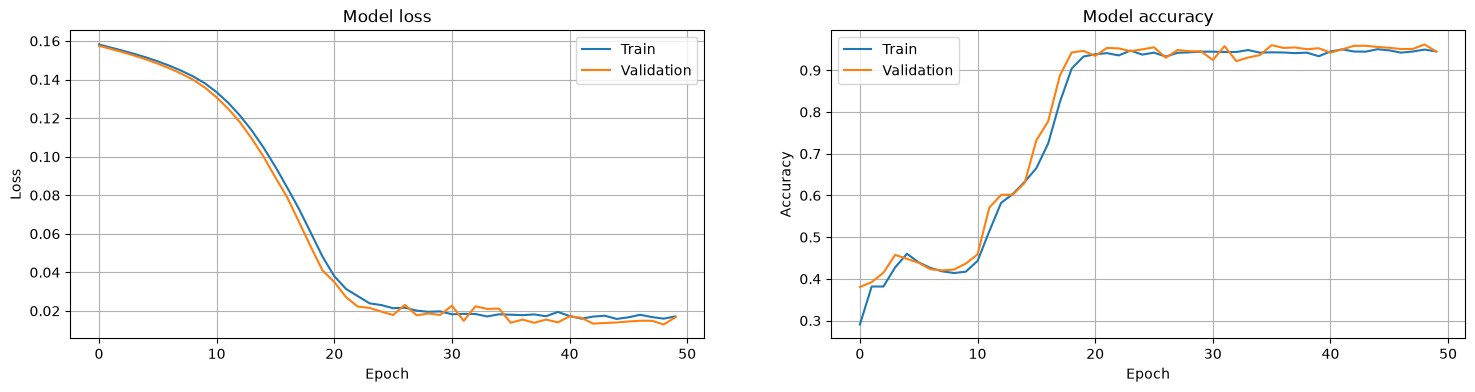

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Model performance:
	Train loss:     0.0172
	Train accuracy: 94.10
	Test loss:      0.0180
	Test accuracy:  93.91


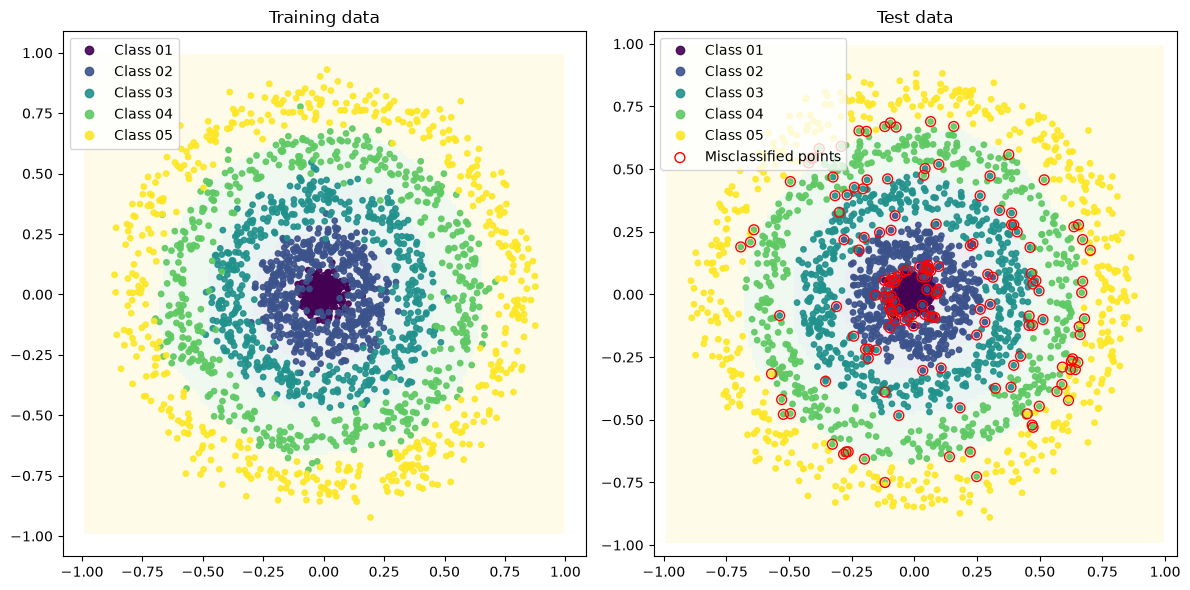

In [16]:
import importlib
import torch_mlp
importlib.reload(torch_mlp)

import torch
import torch.nn as nn

# Uncomment to be able to change data specification (instead of having to run the above cell every time)
#data.generate(dataset='linear', N_train=512, N_test=512, K=2, sigma=0.1) # Task 1.1

# Task 1.2: Polar dataset with 2 classes
#data.generate(dataset='polar', N_train=512, N_test=512, K=2, sigma=0.1)  # Task 1.2

# Task 1.3: Polar dataset with 5 classes
data.generate(dataset='polar', N_train=512, N_test=512, K=5, sigma=0.05) # Task 1.3

# Hyper-parameters
hidden_layers = 10     # The number of hidden layers in the network (total number of layers will be L=hidden_layers+1)
layer_width = 50       # The number of neurons in each hidden layer
activation = 'relu' # Activation function of hidden layers
init = lambda w: nn.init.normal_(w, mean=0.0, std=0.2) # Initialization method (starting point for the optimization)
epochs = 50            # Number of epochs for the training
batch_size = 16      # Batch size to use in training
loss = nn.MSELoss()   # Loss function

# The PyTorch MLP model, set up with the specified hyper parameters
model_t = torch_mlp.TorchMLP(K=data.K, hidden_layers=hidden_layers, layer_width=layer_width,
                             activation=activation, init=init, verbose=True)

# Optimizer (needs the parameters of the model) and an optional learning rate scheduler
opt = torch.optim.SGD(model_t.parameters(), lr=0.01, momentum=0.1)

# Data loaders, which provide the data in batches
train_loader = torch_mlp.make_loader(data.x_train, data.y_train_oh, batch_size, shuffle=True)
val_loader = torch_mlp.make_loader(data.x_valid, data.y_valid_oh, batch_size)

# Train the model a certain number of epochs with a specified batch size
log = fit(model_t, train_loader, val_loader, loss, opt, epochs=epochs)

# Plot the training progress
torch_mlp.plot_training(log)

# Evaluate the model (loss and accuracy on the training and test data)
torch_mlp.evaluate(model_t, data, loss)

# Plot the dataset with decision boundaries generated by the trained model
data.plot_classifier(model_t)

### Our MLP
To make sure our implementation of the MLP works as intended, we can run inference using the weights we trained with PyTorch. Then we can see if we get the same results in terms of accuracy and the decision boundaries generated by the model.

#### Task 2
Implement the "activation", "setup_model", "feedforward", and "evaluate" functions in "mlp.py". Run this cell and compare the results to the results generated by the PyTorch model in the previous cell (compare number of weights, classification loss/accuracy, and the plots with decision boundaries). Test this for different specifications of the model in the previous cell (number of hidden layers, layer width, and activation function)

#### Task 3
Use the linear dataset with 2 classes (K=2). Change the specification of the model parameters. Instead of extracting the weights from the PyTorch model, you should manually specify a weight matrix (2x2) and a bias vector (2x1), i.e. no hidden layers. Remember that each layer is supposed to be an item in a list, which means that you need to specify the weight matrix and the bias vector in separate 1-item lists. As we only have one layer, it will use the 'softmax' activation function.
* Manually derive weights and biases to specify a model that draws a decision boundary at x2 = 1-x1. What is the simplest possible solution? How many additional solutions are possible?
* How can you, in the simplest way, change the weights/biases to switch the predicted class labels?
* By writing out the output of the MLP, motivate why your choice of weights and biases creates a decision boundary at x2 = 1-x1. Can you find a general formula for specifying which combinations of weights and biases will generate the decision boundary?

Data specification:
	Dataset type:           linear
	Number of classes:      2
	Std of classes:         0.25
	Training data shape:    (1024, 2)
	Validation data shape:  (1024, 2)
	Test data shape:        (1024, 2)


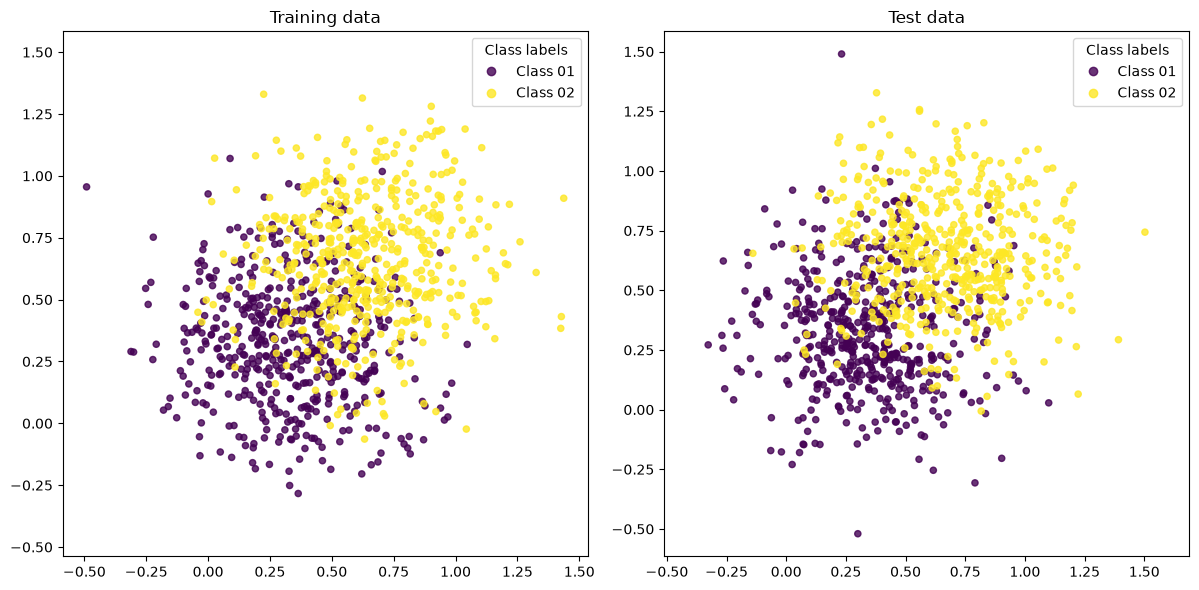

Number of hidden layers:  0
Number of model weights:  6
Model performance:
	Train loss:     0.1865
	Train accuracy: 0.81
	Test loss:      0.1832
	Test accuracy:  0.83


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


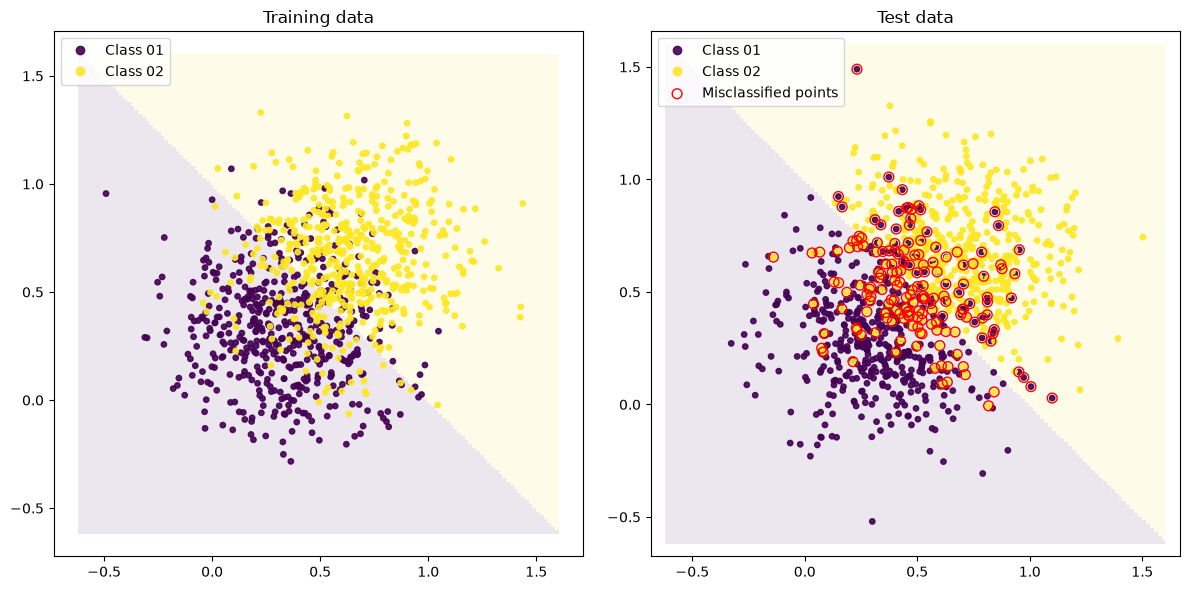

In [37]:
import numpy as np
import mlp
import importlib
importlib.reload(mlp)

# Get the weight matrices and biases of the trained PyTorch model
#W, b = model_t.get_weights()

# generating some new data with 2 classes
data.generate(dataset='linear', N_train=512, N_test=512, K=2, sigma=0.25)

# plot the dataset
data.plot()

# Task 3: specify a weight matrix and a bias vector
W = [np.array([[0., 0.],
               [1., 1.]])]

b = [np.array([[0.],
               [ -1.]])]

activation = 'linear'

# This is our implementation of an MLP, which we set to use the dataset we generated
model = mlp.MLP(data)

# Assign the weights and biases to the MLP and specify the activation function
model.setup_model(W, b, activation=activation)

# Evaluate the model (accuracy on the training and test data)
model.evaluate()

# Plot the dataset with decision boundaries generated by our MLP
data.plot_classifier(model)